In [86]:
from pathlib import Path
import re
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from skimage.restoration import unwrap_phase


In [87]:
def load_monitor_data(path):
    """Load a Lumerical E/H export; E/H keep (x, y, z, f, component) axes."""
    path = Path(path)
    with h5py.File(path, "r") as mat:
        coordinates = {key: mat[f"E/{key}"][()].ravel()
                       for key in ("x", "y", "z", "f", "lambda")}
        shape = tuple(coordinates[key].size for key in ("x", "y", "z", "f")) + (3,)
        if shape[0] != 1 or shape[3] != 1:
            raise ValueError(f"{path.name}: select a single x plane and frequency.")
        fields = {}
        for name in ("E", "H"):
            for key, coordinate in coordinates.items():
                other = mat[f"{name}/{key}"][()].ravel()
                if other.shape != coordinate.shape or not np.allclose(other, coordinate, rtol=1e-10, atol=0):
                    raise ValueError(f"{path.name}: E/H {key} coordinates do not match.")
            raw = mat[f"{name}/{name}"][()].T
            values = raw["real"] + 1j * raw["imag"] if raw.dtype.names else raw.astype(complex)
            # Reverse HDF5 dimensions, then restore MATLAB's spatial flattening order.
            fields[name] = values.reshape(shape, order="F")
    monitor = {**coordinates, **fields, "path": path,
               "wavelength": coordinates["lambda"],
               "y_um": coordinates["y"] * 1e6, "z_um": coordinates["z"] * 1e6}
    for name, field in fields.items():
        for component, axis in enumerate("xyz"):
            monitor[name + axis] = field[0, :, :, 0, component]
    monitor["intensity"] = np.sum(np.abs(fields["E"][0, :, :, 0, :])**2, axis=-1)
    return monitor


def load_mesh_sweep(parent_path, lens_name="lens.mat", slab_name="slab.mat", dividers=None):
    """Discover complete global_lambda_N folders and load them in numeric N order."""
    parent_path = Path(parent_path)
    selected = None if dividers is None else {float(value) for value in dividers}
    folders = {}
    for folder in parent_path.glob("global_lambda_*"):
        match = re.fullmatch(r"global_lambda_(\d+(?:\.\d+)?)", folder.name)
        if not folder.is_dir() or match is None:
            continue
        divider = float(match.group(1))
        if divider <= 0 or (selected is not None and divider not in selected):
            continue
        missing = [name for name in (slab_name, lens_name) if not (folder / name).is_file()]
        if missing:
            print(f"Skipping {folder.name}: missing {', '.join(missing)}")
            continue
        if divider in folders:
            raise ValueError(f"More than one folder corresponds to mesh divider {divider:g}.")
        folders[divider] = folder
    if selected is not None and selected.difference(folders):
        raise FileNotFoundError(f"Missing complete folders for dividers: {sorted(selected.difference(folders))}")
    if not folders:
        raise FileNotFoundError(f"No complete global_lambda_N folders found in {parent_path}.")
    meshes = {
        divider: {"Slab": load_monitor_data(folder / slab_name),
                  "Lens": load_monitor_data(folder / lens_name)}
        for divider, folder in sorted(folders.items())
    }
    frequency = next(iter(meshes.values()))["Lens"]["f"][0]
    for divider, monitors in meshes.items():
        for name, monitor in monitors.items():
            if not np.isclose(monitor["f"][0], frequency, rtol=1e-9, atol=0):
                raise ValueError(f"Mesh {divider:g}, {name}: frequency differs from the other exports.")
    return meshes


def summarize_mesh_sweep(meshes):
    """Report the actual monitor positions and sampling grids for each mesh."""
    wavelength_nm = next(iter(meshes.values()))["Lens"]["wavelength"][0] * 1e9
    print(f"Loaded mesh dividers: {', '.join(f'{n:g}' for n in meshes)}; wavelength = {wavelength_nm:.1f} nm")
    print(f"{'Divider N':>10} {'Slab x (µm)':>13} {'Lens x (µm)':>13} {'Lens grid (y, z)':>18}")
    for divider, monitors in meshes.items():
        print(f"{divider:10g} {monitors['Slab']['x'][0] * 1e6:13.5f} "
              f"{monitors['Lens']['x'][0] * 1e6:13.5f} {str(monitors['Lens']['intensity'].shape):>18}")


def get_origin_cuts(monitor, quantity="intensity", center_um=(0.0, 0.0)):
    """Extract y and z cuts through the nearest sampled (y, z) coordinates."""
    iy = int(np.argmin(np.abs(monitor["y_um"] - center_um[0])))
    iz = int(np.argmin(np.abs(monitor["z_um"] - center_um[1])))
    values = monitor[quantity]
    return {
        "y": {"position_um": monitor["y_um"], "values": values[:, iz],
              "origin_index": iy, "fixed_um": monitor["z_um"][iz]},
        "z": {"position_um": monitor["z_um"], "values": values[iy, :],
              "origin_index": iz, "fixed_um": monitor["y_um"][iy]},
    }


def load_lens_ycut(path, component="Ey"):
    """Read one field component along y at sampled z nearest zero, without full maps."""
    path = Path(path)
    if component not in ("Ex", "Ey", "Ez", "Hx", "Hy", "Hz"):
        raise ValueError("Choose an E/H Cartesian component, e.g. Ey.")
    group, component_index = component[0], "xyz".index(component[1])
    with h5py.File(path, "r") as mat:
        x = mat[f"{group}/x"][()].ravel()
        y = mat[f"{group}/y"][()].ravel()
        z = mat[f"{group}/z"][()].ravel()
        frequency = mat[f"{group}/f"][()].ravel()
        if x.size != 1 or frequency.size != 1:
            raise ValueError(f"{path}: select a single x plane and frequency.")
        iz = int(np.argmin(np.abs(z)))
        dataset = mat[f"{group}/{group}"]
        if dataset.shape != (3, y.size * z.size):
            raise ValueError(f"{path}: unexpected vector-field storage shape {dataset.shape}.")
        # MATLAB flattens y first for a single-x plane.
        raw = dataset[component_index, iz * y.size:(iz + 1) * y.size]
        field_cut = raw["real"] + 1j * raw["imag"] if raw.dtype.names else raw.astype(complex)
    return {"y_um": y * 1e6, "field_cut": field_cut,
            "x_um": float(x[0] * 1e6), "z_um": float(z[iz] * 1e6),
            "frequency_hz": float(frequency[0]), "path": path, "component": component}


def load_lens_ycut_group(parent_path, z_divider, lens_name="lens.mat", component="Ey"):
    """Load only the Lens y cut nearest z=0 from each xy_N_z_M folder.

    Reads one component and one z slice directly from HDF5, rather than loading
    the full E/H maps for every anisotropic mesh.
    """
    if component not in ("Ex", "Ey", "Ez", "Hx", "Hy", "Hz"):
        raise ValueError("Choose an E/H Cartesian component, e.g. Ey.")
    folders = {}
    for folder in Path(parent_path).glob("xy_*_z_*"):
        match = re.fullmatch(r"xy_(\d+(?:\.\d+)?)_z_(\d+(?:\.\d+)?)", folder.name)
        if not folder.is_dir() or match is None:
            continue
        xy_value, z_value = map(float, match.groups())
        if z_value != float(z_divider):
            continue
        path = folder / lens_name
        if not path.is_file():
            print(f"Skipping {folder.name}: missing {lens_name}")
            continue
        if xy_value in folders:
            raise ValueError(f"Duplicate xy divider {xy_value:g} in z group {z_divider:g}.")
        folders[xy_value] = path
    if not folders:
        raise FileNotFoundError(f"No Lens exports found for z divider {z_divider:g} in {parent_path}.")
    cuts = {}
    for xy_value, path in sorted(folders.items()):
        with h5py.File(path, "r") as mat:
            for key, expected in (("mesh_divider_x_y", xy_value), ("mesh_divider_z", z_divider)):
                if key in mat and not np.isclose(float(mat[key][()].squeeze()), expected, rtol=1e-10, atol=0):
                    raise ValueError(f"{path}: saved {key} does not match its folder label.")
        cuts[xy_value] = {**load_lens_ycut(path, component), "z_divider": float(z_divider)}
    reference_frequency = next(iter(cuts.values()))["frequency_hz"]
    if not all(np.isclose(cut["frequency_hz"], reference_frequency, rtol=1e-9, atol=0)
               for cut in cuts.values()):
        raise ValueError("Compare the same frequency across xy mesh dividers.")
    print(f"Lens, z divider {z_divider:g}: loaded xy dividers "
          + ", ".join(f"{value:g}" for value in cuts))
    return cuts


def load_auto_xy_ycut_cases(parent_path, z_step_nm=12, lens_name="lens.mat", component="Ey"):
    """Discover automatic xy accuracy folders at a fixed z step, in numeric order."""
    folders = []
    for folder in Path(parent_path).glob("xy_lambda_o*_z_*nm"):
        match = re.fullmatch(r"xy_lambda_o(\d+)_z_(\d+(?:\.\d+)?)nm", folder.name)
        if not folder.is_dir() or match is None:
            continue
        accuracy, z_nm = int(match.group(1)), float(match.group(2))
        if z_nm != float(z_step_nm):
            continue
        if not (folder / lens_name).is_file():
            print(f"Skipping {folder.name}: missing {lens_name}")
            continue
        folders.append((accuracy, folder))
    if not folders:
        raise FileNotFoundError(f"No automatic xy Lens exports at z step {z_step_nm:g} nm.")
    return {
        f"Auto xy accuracy {accuracy}, z {z_step_nm:g} nm": load_lens_ycut(folder / lens_name, component)
        for accuracy, folder in sorted(folders)
    }




In [ ]:
def gaussian_intensity(position, amplitude, center, waist, background):
    """Gaussian intensity; waist is the 1/e² radius in the coordinate units."""
    return background + amplitude * np.exp(-2 * ((position - center) / waist)**2)


def fit_gaussian(position_um, intensity):
    """Fit a Gaussian plus constant background; report radii in µm and R²."""
    scale = float(np.max(intensity))
    if not np.isfinite(scale) or scale <= 0:
        raise ValueError("A Gaussian fit requires a positive intensity maximum.")
    normalized = intensity / scale
    peak = int(np.argmax(normalized))
    baseline = max(0.0, float(normalized.min()))
    half_height = baseline + (1 - baseline) / 2
    left = right = peak
    while left > 0 and normalized[left - 1] >= half_height:
        left -= 1
    while right < position_um.size - 1 and normalized[right + 1] >= half_height:
        right += 1
    spacing = np.min(np.abs(np.diff(position_um)))
    guess = max(position_um[right] - position_um[left], spacing) / np.sqrt(2 * np.log(2))
    parameters, _ = curve_fit(
        gaussian_intensity, position_um, normalized,
        p0=[1 - baseline, position_um[peak], guess, baseline],
        bounds=([0, position_um.min(), spacing / 100, 0],
                [np.inf, position_um.max(), np.inf, np.inf]), maxfev=20000,
    )
    predicted = gaussian_intensity(position_um, *parameters)
    total = np.sum((normalized - normalized.mean())**2)
    r_squared = 1 - np.sum((normalized - predicted)**2) / total if total > 0 else np.nan
    parameters[[0, 3]] *= scale
    return {"parameters": parameters, "waist_um": parameters[2],
            "fwhm_um": parameters[2] * np.sqrt(2 * np.log(2)),
            "center_um": parameters[1], "r_squared": r_squared}


def relative_phase(field_cut, origin_index, threshold=1e-3):
    """Unwrap phase, reference it to the cut center, and mask weak-field points."""
    intensity = np.abs(field_cut)**2
    center_intensity = intensity[origin_index]
    if not np.isfinite(center_intensity) or center_intensity <= 0:
        raise ValueError("The chosen component must have nonzero intensity at the reference point.")
    phase = np.unwrap(np.angle(field_cut))
    phase -= phase[origin_index]
    return np.where(intensity >= threshold * center_intensity, phase, np.nan)


def fit_lens_meshes(meshes, center_um=(0.0, 0.0)):
    """Fit only Lens y/z cuts at every mesh divider; return results keyed by N."""
    results = {
        divider: {direction: fit_gaussian(cut["position_um"], cut["values"])
                  for direction, cut in get_origin_cuts(monitors["Lens"], center_um=center_um).items()}
        for divider, monitors in meshes.items()
    }
    print("Lens Gaussian 1/e² intensity radii; all intensity samples are fitted.")
    print(f"{'Divider N':>10} {'w_y (µm)':>11} {'w_z (µm)':>11} {'R²_y':>9} {'R²_z':>9}")
    for divider, fits in results.items():
        fy, fz = fits["y"], fits["z"]
        print(f"{divider:10g} {fy['waist_um']:11.4f} {fz['waist_um']:11.4f} "
              f"{fy['r_squared']:9.4f} {fz['r_squared']:9.4f}")
    return results


def relative_phase_map(monitor, component="Ey", center_um=(0.0, 0.0), wrapped=False):
    """Full y-z phase map referenced to the center; no intensity threshold."""
    field = monitor[component]
    iy = int(np.argmin(np.abs(monitor["y_um"] - center_um[0])))
    iz = int(np.argmin(np.abs(monitor["z_um"] - center_um[1])))
    if not np.all(np.isfinite(field)):
        raise ValueError("Phase maps require finite field samples.")
    if wrapped:
        return np.angle(field * np.exp(-1j * np.angle(field[iy, iz])))
    phase = unwrap_phase(np.angle(field), seed=0)
    return phase - phase[iy, iz]


def compute_phase_convergence(meshes, component="Ey", threshold=1e-3,
                              center_y_um=0.0, y_range_um=None):
    """Mean absolute change of the unwrapped y-cut phase versus the preceding mesh.

    Every cut is at sampled z nearest 0 µm and referenced to sampled y nearest
    center_y_um. All comparisons use the same y grid and validity mask for each
    monitor. Integration excludes masked gaps instead of bridging them.
    """
    dividers = np.array(sorted(meshes))
    if dividers.size < 2:
        raise ValueError("Load at least two mesh dividers for phase convergence.")
    results = {}
    for name in ("Slab", "Lens"):
        cuts, phases = {}, {}
        for divider in dividers:
            cut = get_origin_cuts(meshes[divider][name], component, (center_y_um, 0.0))["y"]
            if not np.all(np.diff(cut["position_um"]) > 0):
                raise ValueError("Phase convergence requires increasing y coordinates.")
            cuts[divider] = cut
            phases[divider] = relative_phase(cut["values"], cut["origin_index"], threshold)
        lower = max(cut["position_um"].min() for cut in cuts.values())
        upper = min(cut["position_um"].max() for cut in cuts.values())
        if y_range_um is not None:
            lower, upper = max(lower, y_range_um[0]), min(upper, y_range_um[1])
        # Use the finest mesh's y samples as a common grid, without extrapolation.
        reference_y = cuts[dividers[-1]]["position_um"]
        y_common = reference_y[(reference_y >= lower) & (reference_y <= upper)]
        if y_common.size < 2:
            raise ValueError(f"{name}: not enough overlapping y samples.")
        phase_grid = np.array([
            np.interp(y_common, cuts[divider]["position_um"], phases[divider])
            for divider in dividers
        ])
        # Interpolating NaNs preserves gaps when either bracketing sample is weak.
        valid = np.all(np.isfinite(phase_grid), axis=0)
        segments = valid[:-1] & valid[1:]
        dy = np.diff(y_common)
        valid_length = np.sum(dy[segments])
        if valid_length <= 0:
            raise ValueError(f"{name}: no shared valid y intervals; adjust threshold or y_range_um.")
        differences = phase_grid[1:] - phase_grid[:-1]
        absolute = np.abs(differences)
        segment_means = (absolute[:, :-1] + absolute[:, 1:]) / 2
        mean_absolute = np.sum(segment_means[:, segments] * dy[segments], axis=1) / valid_length
        results[name] = {
            "all_dividers": dividers.copy(), "previous_divider": dividers[:-1].copy(),
            "divider": dividers[1:].copy(), "mean_abs_rad": mean_absolute,
            "y_um": y_common, "valid_mask": valid, "valid_length_um": valid_length,
        }
        print(f"{name}: same valid y region for all meshes; length = {valid_length:.4f} µm")
        print(f"{'Previous N':>12} {'Current N':>12} {'Mean |Δphase| (rad)':>22}")
        for previous, current, error in zip(dividers[:-1], dividers[1:], mean_absolute):
            print(f"{previous:12g} {current:12g} {error:22.6g}")
    return results


def prepare_monitor_comparison(reference_monitors, comparison_folder, reference_label,
                               lens_name="lens.mat", slab_name="slab.mat"):
    """Load a named Slab/Lens case and check its frequency against a reference."""
    folder = Path(comparison_folder)
    cases = {
        reference_label: reference_monitors,
        folder.name: {"Slab": load_monitor_data(folder / slab_name),
                      "Lens": load_monitor_data(folder / lens_name)},
    }
    frequency = reference_monitors["Lens"]["f"][0]
    print(f"Comparison at λ = {reference_monitors['Lens']['wavelength'][0] * 1e9:.1f} nm")
    for case, monitors in cases.items():
        for name, monitor in monitors.items():
            if not np.isclose(monitor["f"][0], frequency, rtol=1e-9, atol=0):
                raise ValueError(f"{case}, {name}: frequencies do not match.")
            print(f"  {case}, {name}: x = {monitor['x'][0] * 1e6:.5f} µm; "
                  f"y–z grid {monitor['intensity'].shape}")
    return cases


def fit_lens_cases(cases, center_um=(0.0, 0.0)):
    """Fit Lens cuts for named cases; report 1/e² radii and change from the first case."""
    results = {
        case: {direction: fit_gaussian(cut["position_um"], cut["values"])
               for direction, cut in get_origin_cuts(monitors["Lens"], center_um=center_um).items()}
        for case, monitors in cases.items()
    }
    print("Lens Gaussian 1/e² intensity radii; all intensity samples are fitted.")
    print(f"{'Case':<28} {'w_y (µm)':>11} {'w_z (µm)':>11} {'R²_y':>9} {'R²_z':>9}")
    for case, fits in results.items():
        fy, fz = fits["y"], fits["z"]
        print(f"{case:<28} {fy['waist_um']:11.4f} {fz['waist_um']:11.4f} "
              f"{fy['r_squared']:9.4f} {fz['r_squared']:9.4f}")
    reference = next(iter(results))
    for case in list(results)[1:]:
        changes = {direction: 100 * (results[case][direction]["waist_um"] /
                                    results[reference][direction]["waist_um"] - 1)
                   for direction in ("y", "z")}
        print(f"{case} relative to {reference}: Δw_y = {changes['y']:+.3f}%, "
              f"Δw_z = {changes['z']:+.3f}%")
    return results


def lens_yphase_differences(reference, cases, threshold=1e-3, center_y_um=0.0):
    """Return unwrapped, center-referenced case minus reference phases along y.

    Interpolate each case onto the reference y grid over their overlap. NaNs
    preserve weak-field gaps in either profile. Uses the exported x planes.
    """
    reference_y = reference["y_um"]
    if not np.all(np.diff(reference_y) > 0):
        raise ValueError("The reference y coordinates must be increasing.")
    reference_origin = int(np.argmin(abs(reference_y - center_y_um)))
    reference_phase = relative_phase(reference["field_cut"], reference_origin, threshold)
    differences = {}
    for label, case in cases.items():
        if case["component"] != reference["component"]:
            raise ValueError(f"{label}: choose the same field component as the reference.")
        if not np.isclose(case["frequency_hz"], reference["frequency_hz"], rtol=1e-9, atol=0):
            raise ValueError(f"{label}: frequency differs from the reference.")
        position = case["y_um"]
        if not np.all(np.diff(position) > 0):
            raise ValueError(f"{label}: y coordinates must be increasing.")
        origin = int(np.argmin(abs(position - center_y_um)))
        phase = relative_phase(case["field_cut"], origin, threshold)
        overlap = (reference_y >= position.min()) & (reference_y <= position.max())
        if np.count_nonzero(overlap) < 2:
            raise ValueError(f"{label}: fewer than two overlapping y samples.")
        y_common = reference_y[overlap]
        phase_common = np.interp(y_common, position, phase)
        difference = phase_common - reference_phase[overlap]
        if not np.any(np.isfinite(difference)):
            raise ValueError(f"{label}: no shared phase samples above the intensity threshold.")
        differences[label] = {"y_um": y_common, "difference_rad": difference,
                              "case_phase_rad": phase_common,
                              "reference_phase_rad": reference_phase[overlap],
                              "case_x_um": case["x_um"], "case_z_um": case["z_um"],
                              "reference_x_um": reference["x_um"],
                              "reference_z_um": reference["z_um"]}
    return differences


def mean_absolute_yphase_difference(differences, y_range_um=None):
    """Spatial mean |delta phase| on the same above-threshold y region for all cases.

    Integrate piecewise-linear residuals by distance, excluding masked gaps.
    This avoids bias from nonuniform sampling or cancellation of opposite signs.
    """
    if not differences:
        raise ValueError("Provide at least one phase difference cut.")
    lower = max(cut["y_um"].min() for cut in differences.values())
    upper = min(cut["y_um"].max() for cut in differences.values())
    if y_range_um is not None:
        lower, upper = max(lower, y_range_um[0]), min(upper, y_range_um[1])
    reference_y = next(iter(differences.values()))["y_um"]
    y = reference_y[(reference_y >= lower) & (reference_y <= upper)]
    if y.size < 2 or not np.all(np.diff(y) > 0):
        raise ValueError("Need at least two increasing samples in the shared y domain.")
    values = np.array([np.interp(y, cut["y_um"], cut["difference_rad"])
                       for cut in differences.values()])
    valid = np.all(np.isfinite(values), axis=0)
    segments = valid[:-1] & valid[1:]
    dy = np.diff(y)[segments]
    length = dy.sum()
    if length <= 0:
        raise ValueError("No shared above-threshold y intervals available for averaging.")
    left, right = values[:, :-1][:, segments], values[:, 1:][:, segments]
    area = 0.5 * (abs(left) + abs(right)) * dy
    # Integrate |linear phase| exactly when a segment crosses zero.
    crossing = ((left < 0) & (right > 0)) | ((left > 0) & (right < 0))
    denominator = abs(left) + abs(right)
    crossed_area = np.zeros_like(area)
    np.divide(left**2 + right**2, 2 * denominator, out=crossed_area, where=crossing)
    area = np.where(crossing, crossed_area * dy, area)
    means = area.sum(axis=1) / length
    results = dict(zip(differences, means))
    active = np.flatnonzero(segments)
    print(f"Shared above-threshold y region: {y[active[0]]:.4f} to {y[active[-1]+1]:.4f} µm; "
          f"total valid length = {length:.4f} µm (masked gaps excluded).")
    print("Mean absolute phase difference = integral |delta phase| dy / valid length.")
    for label, value in results.items():
        print(f"{label}: {value:.6f} rad")
    return {"mean_abs_rad": results, "y_um": y, "valid_mask": valid,
            "valid_segments": segments, "valid_length_um": float(length)}


In [89]:
def mesh_colors(meshes):
    """Use the same mesh colors in the intensity-fit and phase figures."""
    dividers = sorted(meshes)
    palette = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    colors = palette[:len(dividers)] if len(dividers) <= len(palette) else plt.cm.viridis(np.linspace(0, 1, len(dividers)))
    return dict(zip(dividers, colors))


def mesh_plot_axes(meshes, rows):
    """Two-column plots with a separate legend row, included in notebook cropping."""
    legend_columns = min(len(meshes), 4)
    legend_rows = int(np.ceil(len(meshes) / legend_columns))
    fig = plt.figure(figsize=(12, 4 * rows + 0.45 * legend_rows), constrained_layout=True)
    grid = fig.add_gridspec(rows + 1, 2, height_ratios=[0.16 * legend_rows] + [1] * rows)
    legend_ax = fig.add_subplot(grid[0, :])
    legend_ax.set_axis_off()
    axes = np.empty((rows, 2), dtype=object)
    for row in range(rows):
        for col in range(2):
            axes[row, col] = fig.add_subplot(grid[row + 1, col])
    return fig, axes, legend_ax


def plot_mesh_intensity_maps(meshes, dividers=None, center_um=(0.0, 0.0)):
    """One row per mesh, Slab/Lens columns, independent intensity colorbars."""
    selected = sorted(meshes) if dividers is None else sorted(float(value) for value in dividers)
    if not selected or any(divider not in meshes for divider in selected):
        raise ValueError("Select at least one loaded mesh divider for the intensity maps.")
    fig, axes = plt.subplots(len(selected), 2, figsize=(12, 4.5 * len(selected)),
                             squeeze=False, constrained_layout=True)
    for row, divider in enumerate(selected):
        for col, name in enumerate(("Slab", "Lens")):
            monitor = meshes[divider][name]
            ax = axes[row, col]
            image = ax.pcolormesh(monitor["y_um"], monitor["z_um"], monitor["intensity"].T,
                                  shading="auto", cmap="inferno")
            cuts = get_origin_cuts(monitor, center_um=center_um)
            ax.axvline(cuts["z"]["fixed_um"], color="cyan", linestyle="--", linewidth=0.8)
            ax.axhline(cuts["y"]["fixed_um"], color="cyan", linestyle="--", linewidth=0.8)
            ax.set(xlabel="y (µm)", ylabel="z (µm)",
                   title=f"{name}, λ/{divider:g}: x = {monitor['x'][0] * 1e6:.3f} µm")
            ax.set_aspect("auto")
            ax.set_box_aspect(1)
            fig.colorbar(image, ax=ax, label=r"$|E|^2$ (V$^2$/m$^2$)")
    plt.show()
    return fig


def plot_lens_mesh_fits(meshes, fits, center_um=(0.0, 0.0)):
    """Overlay Lens intensity and fitted Gaussian cuts across mesh dividers."""
    fig, axes, legend_ax = mesh_plot_axes(meshes, rows=1)
    colors = mesh_colors(meshes)
    for divider, monitors in meshes.items():
        for col, (direction, cut) in enumerate(get_origin_cuts(monitors["Lens"], center_um=center_um).items()):
            position, intensity = cut["position_um"], cut["values"]
            ax = axes[0, col]
            ax.plot(position, intensity, color=colors[divider], alpha=0.65, linewidth=1.2,
                    label=f"λ/{divider:g}")
            dense = np.linspace(position.min(), position.max(), 2000)
            ax.plot(dense, gaussian_intensity(dense, *fits[divider][direction]["parameters"]),
                    "--", color=colors[divider])
            fixed_direction = "z" if direction == "y" else "y"
            ax.set(xlabel=f"{direction} (µm)", ylabel=r"$|E|^2$ (V$^2$/m$^2$)",
                   title=f"Lens: {direction} cut at {fixed_direction} = {cut['fixed_um']:.3f} µm")
            ax.margins(x=0.02, y=0.04)
            ax.grid(alpha=0.25)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    legend_ax.legend(handles, labels, loc="center", ncol=min(len(meshes), 4), frameon=False,
                     fontsize="small")
    fig.suptitle("Lens intensity (solid) and Gaussian fits (dashed)")
    plt.show()
    return fig


def plot_waist_convergence(fits):
    """Plot fitted Lens 1/e² radii as a function of numeric mesh divider N."""
    dividers = np.array(sorted(fits))
    colors = mesh_colors(fits)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
    for ax, direction in zip(axes, ("y", "z")):
        radii = np.array([fits[divider][direction]["waist_um"] for divider in dividers])
        ax.plot(dividers, radii, color="gray", linewidth=1, zorder=1)
        ax.scatter(dividers, radii, c=[colors[divider] for divider in dividers], s=55, zorder=2)
        ax.set(xlabel="Mesh divider N (λ/N)", ylabel=fr"$w_{direction}$ (µm)",
               title=f"Lens {direction} radius vs mesh divider")
        if len(dividers) <= 12:
            ax.set_xticks(dividers)
        ax.grid(alpha=0.25)
    fig.suptitle("Gaussian 1/e² intensity radii")
    plt.show()
    return fig


def plot_mesh_phases(meshes, component="Ey", threshold=1e-3, center_um=(0.0, 0.0)):
    """Overlay mesh phases: Slab/Lens rows, y/z columns, without residuals."""
    fig, axes, legend_ax = mesh_plot_axes(meshes, rows=2)
    colors = mesh_colors(meshes)
    phase_cuts = {}
    for divider, monitors in meshes.items():
        phase_cuts[divider] = {}
        for row, name in enumerate(("Slab", "Lens")):
            phase_cuts[divider][name] = {}
            for col, (direction, cut) in enumerate(get_origin_cuts(monitors[name], component, center_um).items()):
                phase = relative_phase(cut["values"], cut["origin_index"], threshold)
                phase_cuts[divider][name][direction] = {"position_um": cut["position_um"], "phase_rad": phase}
                ax = axes[row, col]
                ax.plot(cut["position_um"], phase, color=colors[divider], linewidth=1.5,
                        label=f"λ/{divider:g}")
    for row, name in enumerate(("Slab", "Lens")):
        for col, direction in enumerate(("y", "z")):
            ax = axes[row, col]
            fixed_direction = "z" if direction == "y" else "y"
            fixed = center_um[1] if direction == "y" else center_um[0]
            ax.set(title=f"{name}: {direction} cut at {fixed_direction} = {fixed:g} µm",
                   xlabel=f"{direction} (µm)", ylabel=f"Unwrapped {component} phase (rad)")
            ax.axvline(center_um[col], color="gray", linestyle="--", linewidth=0.8)
            ax.axhline(0, color="gray", linewidth=0.7)
            ax.margins(x=0.02)
            ax.grid(alpha=0.25)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    legend_ax.legend(handles, labels, loc="center", ncol=min(len(meshes), 4), frameon=False,
                     fontsize="small")
    fig.suptitle(f"{component} phase relative to cut center; intensity ≥ {100 * threshold:g}% of center")
    plt.show()
    return phase_cuts, fig


def plot_mesh_phase_maps(meshes, dividers=(10, 26), monitor_names=("Slab", "Lens"),
                         component="Ey", center_um=(0.0, 0.0), wrapped=False):
    """Compare full phase maps: monitor rows and mesh columns, one color scale per row."""
    selected = tuple(float(divider) for divider in dividers)
    if not selected or not monitor_names:
        raise ValueError("Select mesh dividers and monitor names for the phase maps.")
    missing = [divider for divider in selected if divider not in meshes]
    if missing:
        raise ValueError(f"Missing mesh dividers {missing}; rerun the mesh-import cell.")
    phase_maps = {
        divider: {name: relative_phase_map(meshes[divider][name], component, center_um, wrapped)
                  for name in monitor_names}
        for divider in selected
    }
    fig, axes = plt.subplots(len(monitor_names), len(selected),
                             figsize=(6 * len(selected), 4.5 * len(monitor_names)),
                             squeeze=False, sharex=True, sharey=True, constrained_layout=True)
    for row, name in enumerate(monitor_names):
        limit = np.pi if wrapped else max(float(np.max(np.abs(phase_maps[n][name]))) for n in selected)
        limit = limit if limit > 0 else 1.0
        for col, divider in enumerate(selected):
            monitor = meshes[divider][name]
            ax = axes[row, col]
            image = ax.pcolormesh(monitor["y_um"], monitor["z_um"], phase_maps[divider][name].T,
                                  shading="auto", cmap="twilight" if wrapped else "RdBu_r",
                                  vmin=-limit, vmax=limit)
            ax.set(title=f"{name}, λ/{divider:g}: x = {monitor['x'][0] * 1e6:.3f} µm",
                   xlabel="y (µm)", ylabel="z (µm)")
            ax.set_aspect("auto")
            ax.set_box_aspect(1)
        colorbar = fig.colorbar(image, ax=axes[row, :].tolist(),
                               label=f"{'Wrapped' if wrapped else 'Unwrapped'} {component} phase (rad)")
        if wrapped:
            colorbar.set_ticks([-np.pi, 0, np.pi])
            colorbar.set_ticklabels([r"$-\pi$", "0", r"$\pi$"])
    fig.suptitle(f"{component} phase maps relative to (y, z) = ({center_um[0]:g}, {center_um[1]:g}) µm")
    plt.show()
    return phase_maps, fig


def plot_phase_convergence(results, log_y=True):
    """Plot each mesh's mean absolute phase change from the preceding coarser mesh."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
    for ax, name in zip(axes, ("Slab", "Lens")):
        result = results[name]
        dividers, errors = result["divider"], result["mean_abs_rad"]
        colors = mesh_colors(dict.fromkeys(result["all_dividers"]))
        ax.plot(dividers, errors, color="gray", linewidth=1, zorder=1)
        ax.scatter(dividers, errors, c=[colors[n] for n in dividers], s=55, zorder=2)
        if log_y and np.all(errors > 0):
            ax.set_yscale("log")
        else:
            ax.set_ylim(bottom=0)
        ax.set(title=f"{name}: y-cut phase at z = 0 µm", xlabel="Current mesh divider N (λ/N)",
               ylabel="Mean |Δphase| (rad)")
        if len(dividers) <= 12:
            ax.set_xticks(dividers)
        ax.grid(alpha=0.25, which="both")
    fig.suptitle("Phase change relative to the previous coarser mesh")
    plt.show()
    return fig


def plot_lens_case_fits(cases, fits, center_um=(0.0, 0.0)):
    """Overlay Lens intensity and Gaussian fits for named cases."""
    fig, axes, legend_ax = mesh_plot_axes(cases, rows=1)
    colors = mesh_colors(cases)
    for case, monitors in cases.items():
        for col, (direction, cut) in enumerate(get_origin_cuts(monitors["Lens"], center_um=center_um).items()):
            ax = axes[0, col]
            position, intensity = cut["position_um"], cut["values"]
            ax.plot(position, intensity, color=colors[case], alpha=0.65, linewidth=1.2, label=case)
            dense = np.linspace(position.min(), position.max(), 2000)
            ax.plot(dense, gaussian_intensity(dense, *fits[case][direction]["parameters"]),
                    "--", color=colors[case])
            fixed_direction = "z" if direction == "y" else "y"
            ax.set(title=f"Lens: {direction} cut at {fixed_direction} = {cut['fixed_um']:.3f} µm",
                   xlabel=f"{direction} (µm)", ylabel=r"$|E|^2$ (V$^2$/m$^2$)")
            ax.margins(x=0.02, y=0.04)
            ax.grid(alpha=0.25)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    legend_ax.legend(handles, labels, loc="center", ncol=min(len(cases), 2),
                     frameon=False, fontsize="small")
    fig.suptitle("Lens intensity (solid) and Gaussian fits (dashed)")
    plt.show()
    return fig


def plot_case_phases(cases, component="Ey", threshold=1e-3, center_um=(0.0, 0.0)):
    """Overlay case phases in Slab/Lens rows and y/z columns, without residuals."""
    fig, axes, legend_ax = mesh_plot_axes(cases, rows=2)
    colors = mesh_colors(cases)
    phase_cuts = {}
    for case, monitors in cases.items():
        phase_cuts[case] = {}
        for row, name in enumerate(("Slab", "Lens")):
            phase_cuts[case][name] = {}
            for col, (direction, cut) in enumerate(get_origin_cuts(monitors[name], component, center_um).items()):
                phase = relative_phase(cut["values"], cut["origin_index"], threshold)
                phase_cuts[case][name][direction] = {"position_um": cut["position_um"], "phase_rad": phase}
                axes[row, col].plot(cut["position_um"], phase, color=colors[case],
                                    linewidth=1.5, label=case)
    for row, name in enumerate(("Slab", "Lens")):
        for col, direction in enumerate(("y", "z")):
            ax = axes[row, col]
            fixed_direction = "z" if direction == "y" else "y"
            fixed = center_um[1] if direction == "y" else center_um[0]
            ax.set(title=f"{name}: {direction} cut at {fixed_direction} = {fixed:g} µm",
                   xlabel=f"{direction} (µm)", ylabel=f"Unwrapped {component} phase (rad)")
            ax.axvline(center_um[col], color="gray", linestyle="--", linewidth=0.8)
            ax.axhline(0, color="gray", linewidth=0.7)
            ax.margins(x=0.02)
            ax.grid(alpha=0.25)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    legend_ax.legend(handles, labels, loc="center", ncol=min(len(cases), 2),
                     frameon=False, fontsize="small")
    fig.suptitle(f"{component} phase relative to cut center; intensity ≥ {100 * threshold:g}% of center")
    plt.show()
    return phase_cuts, fig


def plot_lens_yphase_comparison(cuts, threshold=1e-3, center_y_um=0.0,
                                title="Planar Lens mesh comparison", labels=None, legend_columns=5):
    """Overlay Lens y-cut phases with a shared center reference and visible legend."""
    if not cuts:
        raise ValueError("Load at least one Lens y cut.")
    frequency = next(iter(cuts.values()))["frequency_hz"]
    if not all(np.isclose(cut["frequency_hz"], frequency, rtol=1e-9, atol=0)
               for cut in cuts.values()):
        raise ValueError("Compare the same frequency across mesh cases.")
    labels = {} if labels is None else labels
    columns = min(len(cuts), legend_columns)
    legend_rows = int(np.ceil(len(cuts) / columns))
    fig = plt.figure(figsize=(10, 5 + 0.35 * legend_rows), constrained_layout=True)
    grid = fig.add_gridspec(2, 1, height_ratios=[0.14 * legend_rows, 1])
    legend_ax = fig.add_subplot(grid[0])
    legend_ax.set_axis_off()
    ax = fig.add_subplot(grid[1])
    colors = mesh_colors(cuts)
    phases = {}
    components = {cut["component"] for cut in cuts.values()}
    if len(components) != 1:
        raise ValueError("Use the same field component for every mesh case.")
    component = next(iter(components))
    for case, cut in cuts.items():
        iy = int(np.argmin(np.abs(cut["y_um"] - center_y_um)))
        phase = relative_phase(cut["field_cut"], iy, threshold)
        phases[case] = {**cut, "phase_rad": phase}
        ax.plot(cut["y_um"], phase, color=colors[case], linewidth=1.5,
                label=labels.get(case, str(case)))
    ax.axvline(center_y_um, color="gray", linestyle="--", linewidth=0.8)
    ax.axhline(0, color="gray", linewidth=0.7)
    ax.set(xlabel="y (µm)", ylabel=f"Unwrapped relative {component} phase (rad)",
           title=f"y cut at z = 0 µm; phase referenced to y = {center_y_um:g} µm")
    ax.margins(x=0.02)
    ax.grid(alpha=0.25)
    handles, labels = ax.get_legend_handles_labels()
    legend_ax.legend(handles, labels, loc="center", ncol=columns, frameon=False, fontsize="small")
    fig.suptitle(title)
    plt.show()
    return phases, fig
def plot_xy_group_yphase(cuts, z_divider, threshold=1e-3, center_y_um=0.0):
    """Overlay unwrapped Lens y-cut phases for one z-mesh group."""
    return plot_lens_yphase_comparison(
        cuts, threshold=threshold, center_y_um=center_y_um,
        title=f"Planar Lens phase: z mesh divider {z_divider:g}",
        labels={xy: f"xy divider {xy:g}" for xy in cuts},
    )


def plot_lens_yphase_differences(reference, cases, threshold=1e-3, center_y_um=0.0):
    """Overlay signed Lens y-cut phase residuals relative to global lambda/42."""
    differences = lens_yphase_differences(reference, cases, threshold, center_y_um)
    fig = plt.figure(figsize=(10, 5.8), constrained_layout=True)
    grid = fig.add_gridspec(2, 1, height_ratios=[0.13, 1])
    legend_ax = fig.add_subplot(grid[0])
    legend_ax.set_axis_off()
    ax = fig.add_subplot(grid[1])
    for label, difference in differences.items():
        ax.plot(difference["y_um"], difference["difference_rad"], linewidth=1.7, label=label)
    ax.axhline(0, color="gray", linewidth=0.9, linestyle="--")
    ax.axvline(center_y_um, color="gray", linewidth=0.8, linestyle=":")
    ax.set(xlabel="y (µm)", ylabel=r"$\Delta\phi = \phi_{\mathrm{auto}}-\phi_{\lambda/42}$ (rad)",
           title=f"Lens {reference['component']}, z = 0 µm; phase referenced to y = {center_y_um:g} µm")
    ax.grid(alpha=0.25)
    ax.margins(x=0.02)
    handles, labels = ax.get_legend_handles_labels()
    legend_ax.legend(handles, labels, loc="center", ncol=min(len(cases), 3),
                     frameon=False, fontsize="small")
    fig.suptitle("Lens phase difference relative to global λ/42 · z mesh step 12 nm")
    print("Signed difference: automatic xy case minus global λ/42, after referencing each phase to its center.")
    print(f"Intensity threshold in both cuts: {100 * threshold:g}% of each cut's central component intensity.")
    print(f"Global λ/42: recorded x = {reference['x_um']:.6f} µm, sampled z = {reference['z_um']:.6g} µm")
    for label, case in cases.items():
        print(f"{label}: recorded x = {case['x_um']:.6f} µm, sampled z = {case['z_um']:.6g} µm")
    plt.show()
    return differences, fig


In [90]:
# Plot style: rerun this cell and the plotting cells after changing these values.
FONT_FAMILY = "Times New Roman"  # Choose an installed font, e.g. "Arial" or "Times New Roman".
FONT_SIZE = 16  # points

plt.rcParams.update({
    "font.family": FONT_FAMILY,
    "savefig.dpi": 600,  # High resolution for exported images.
    "font.size": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE,
    "legend.title_fontsize": FONT_SIZE,
    "figure.titlesize": FONT_SIZE,
})

In [91]:
# Data location and analysis settings.
parent_path = Path("/home/philip_jacobson/Desktop/Planar_lens_scale_1X")
MESH_DIVIDERS = None  # None: load all complete global_lambda_N folders; or select [22, 26].
MAP_DIVIDERS = None  # None: show maps for all loaded meshes; or select [26].
lens_path = "lens.mat"
slab_path = "slab.mat"

CUT_CENTER_UM = (0.0, 0.0)  # (y, z) in µm.
PHASE_COMPONENT = "Ey"
PHASE_INTENSITY_THRESHOLD = 1e-3  # Fraction of the selected component's center intensity.


In [92]:
mesh_data = load_mesh_sweep(parent_path, lens_name=lens_path, slab_name=slab_path,
                            dividers=MESH_DIVIDERS)
summarize_mesh_sweep(mesh_data)
# Example access: mesh_data[22]["Lens"]["Ey"] or mesh_data[26]["Slab"]["H"].


Loaded mesh dividers: 8, 10, 14, 18, 22, 26, 30, 34, 38, 42; wavelength = 729.0 nm
 Divider N   Slab x (µm)   Lens x (µm)   Lens grid (y, z)
         8      10.00000      18.00000         (155, 155)
        10       9.98182      17.98182         (195, 195)
        14      10.01299      18.01299         (271, 271)
        18      10.01215      17.98785         (347, 347)
        22       9.99338      18.00662         (425, 425)
        26      10.00840      17.99160         (501, 501)
        30       9.99515      18.00485         (579, 579)
        34       9.99678      17.99250         (655, 655)
        38      10.00671      18.00288         (731, 731)
        42       9.99740      17.99393         (809, 809)


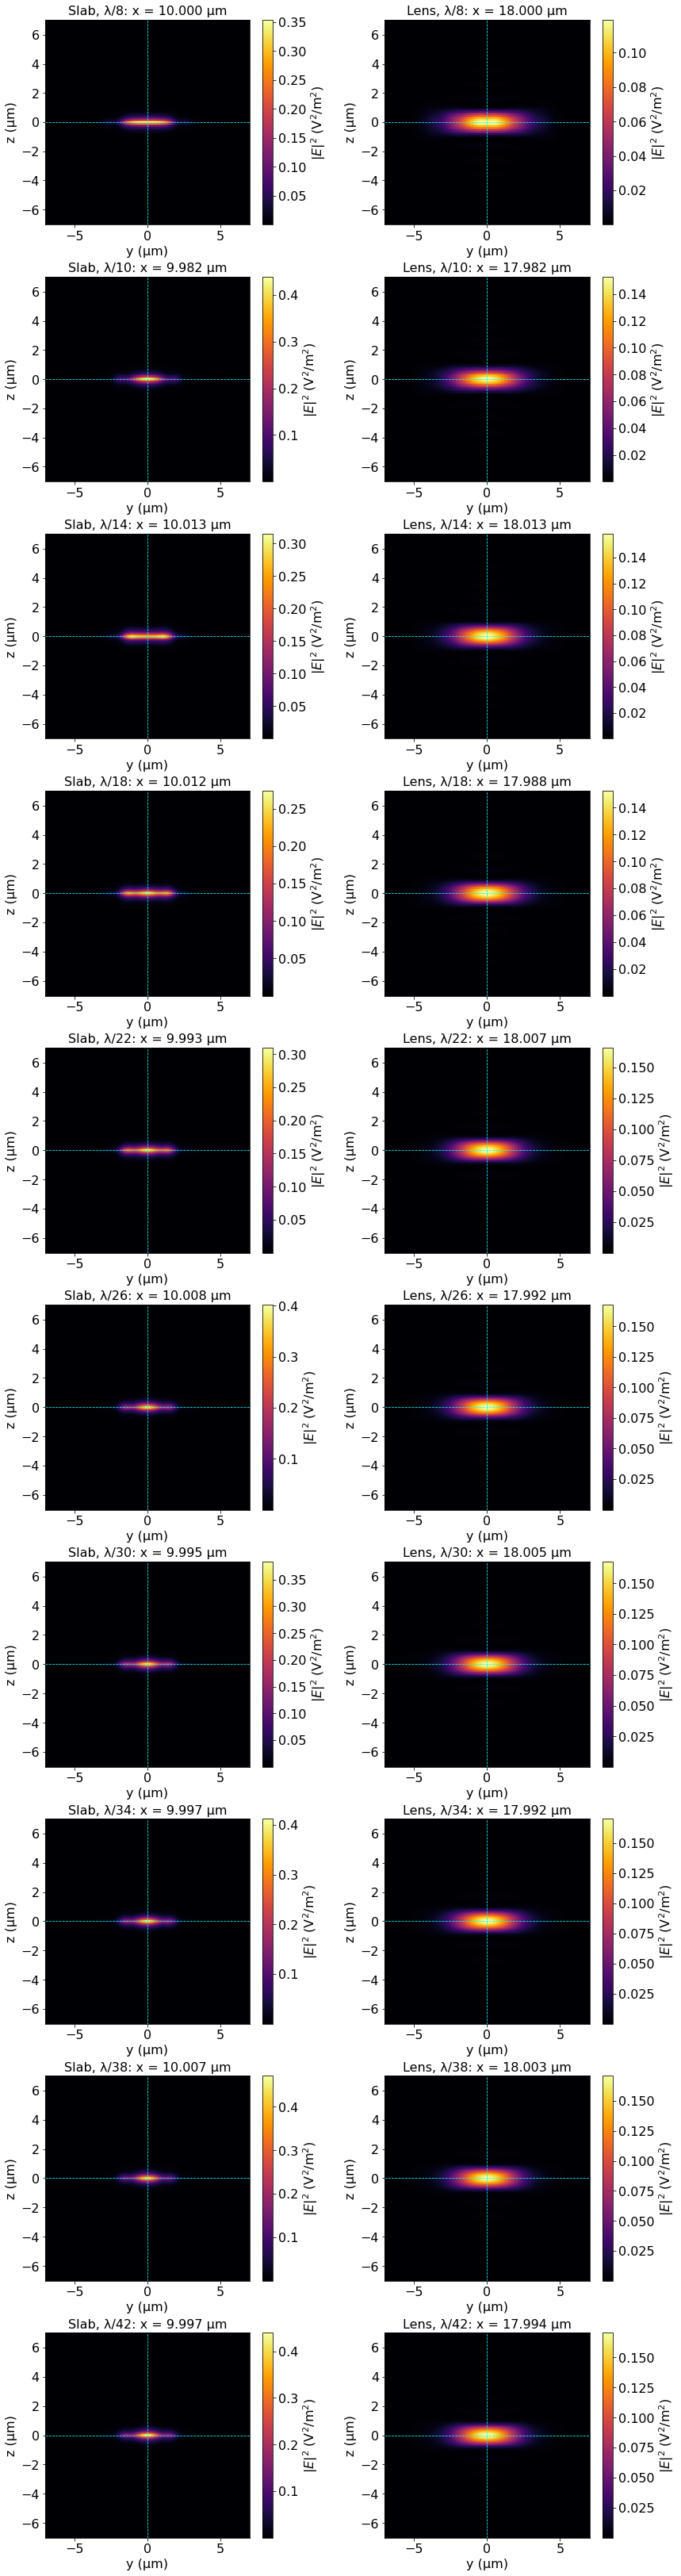

In [93]:
fig_intensity = plot_mesh_intensity_maps(mesh_data, dividers=MAP_DIVIDERS,
                                          center_um=CUT_CENTER_UM)


Lens Gaussian 1/e² intensity radii; all intensity samples are fitted.
 Divider N    w_y (µm)    w_z (µm)      R²_y      R²_z
         8      3.4437      0.8811    0.9986    0.9968
        10      3.1759      0.8382    0.9998    0.9984
        14      3.0893      0.8578    0.9999    0.9947
        18      3.0901      0.8511    0.9998    0.9944
        22      3.0049      0.8546    0.9998    0.9951
        26      2.9921      0.8444    0.9998    0.9955
        30      2.9790      0.8480    0.9998    0.9956
        34      2.9695      0.8420    0.9998    0.9959
        38      2.9613      0.8445    0.9998    0.9960
        42      2.9610      0.8404    0.9997    0.9961


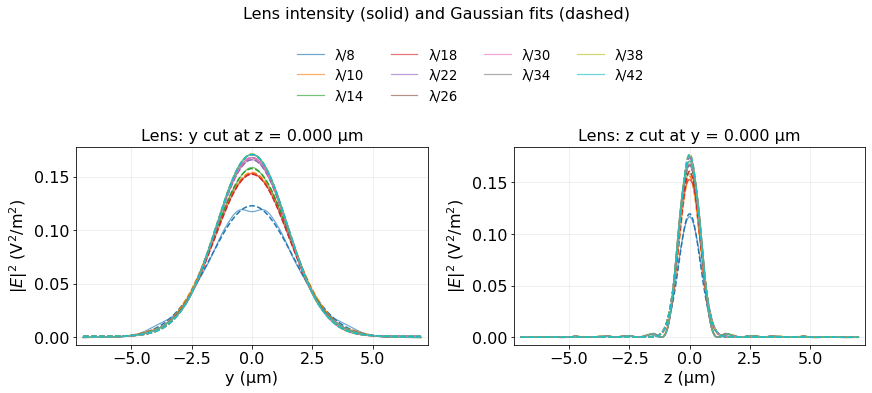

In [94]:
# Fit only Lens; Slab is excluded from the Gaussian waist analysis.
waist_results = fit_lens_meshes(mesh_data, center_um=CUT_CENTER_UM)
fig_waists = plot_lens_mesh_fits(mesh_data, waist_results, center_um=CUT_CENTER_UM)


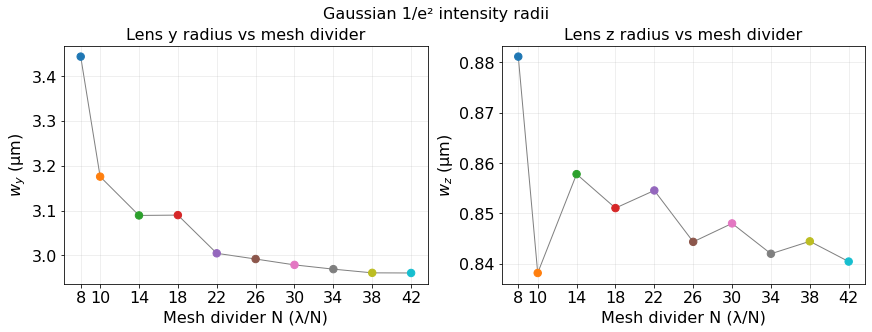

In [95]:
fig_convergence = plot_waist_convergence(waist_results)


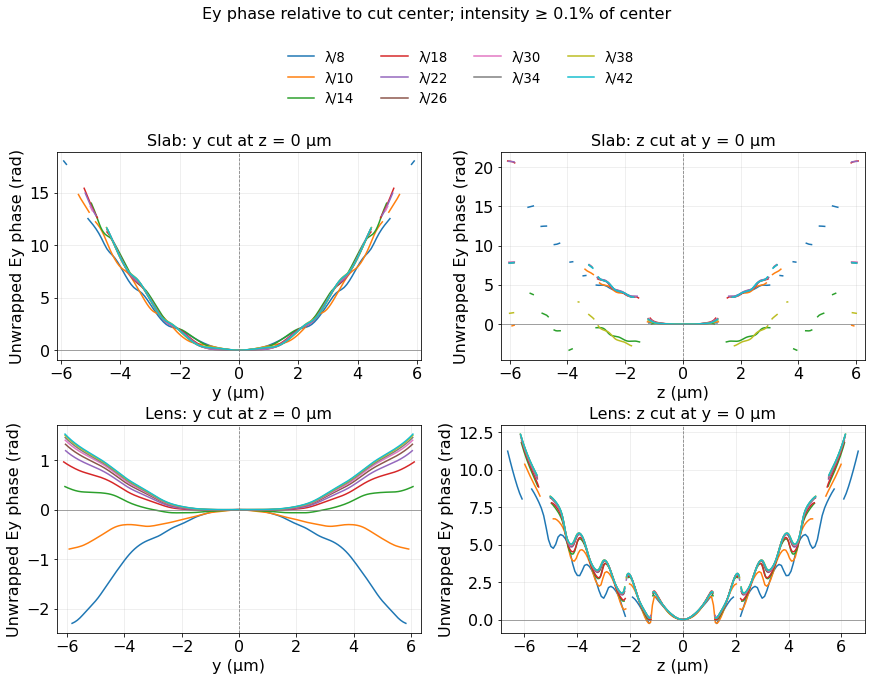

In [96]:
phase_cuts, fig_phases = plot_mesh_phases(
    mesh_data, component=PHASE_COMPONENT, threshold=PHASE_INTENSITY_THRESHOLD,
    center_um=CUT_CENTER_UM,
)


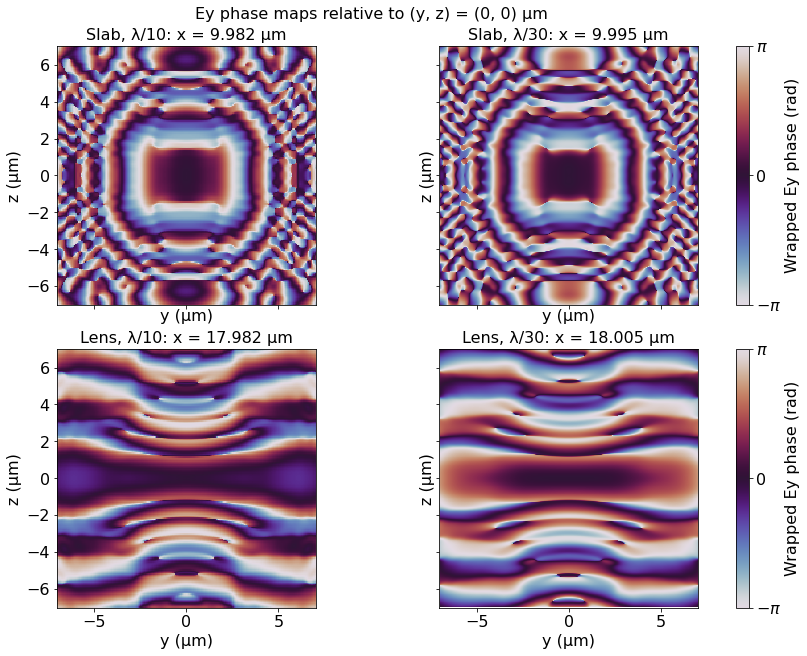

In [97]:
# Full phase maps for λ/10 and λ/26; no intensity threshold is applied.
PHASE_MAP_DIVIDERS = (10,30)
PHASE_MAP_WRAPPED = True  # True displays cyclic phase in [-π, π].
phase_maps, fig_phase_maps = plot_mesh_phase_maps(
    mesh_data, dividers=PHASE_MAP_DIVIDERS, monitor_names=("Slab", "Lens"),
    component=PHASE_COMPONENT, center_um=CUT_CENTER_UM, wrapped=PHASE_MAP_WRAPPED,
)


Slab: same valid y region for all meshes; length = 8.8366 µm
  Previous N    Current N    Mean |Δphase| (rad)
           8           10               0.252079
          10           14               0.461242
          14           18               0.140978
          18           22              0.0400171
          22           26               0.070533
          26           30              0.0270907
          30           34              0.0179968
          34           38               0.040368
          38           42               0.025966
Lens: same valid y region for all meshes; length = 11.6089 µm
  Previous N    Current N    Mean |Δphase| (rad)
           8           10               0.478214
          10           14               0.393977
          14           18               0.162232
          18           22              0.0704597
          22           26              0.0426803
          26           30              0.0256944
          30           34              0.016

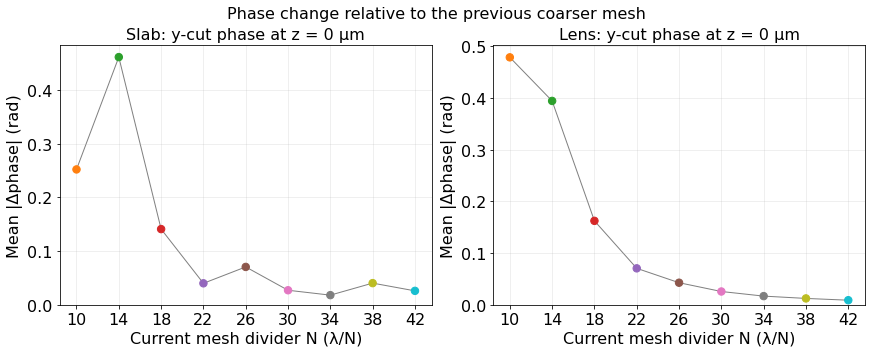

In [98]:
# Average absolute UNWRAPPED y-cut phase difference versus the previous mesh.
# Uses z = 0 µm, the y-center reference, and the existing phase-cut threshold.
PHASE_CONVERGENCE_Y_RANGE_UM = None  # Optional fixed window, e.g. (-3.0, 3.0).
phase_convergence = compute_phase_convergence(
    mesh_data, component=PHASE_COMPONENT, threshold=PHASE_INTENSITY_THRESHOLD,
    center_y_um=CUT_CENTER_UM[0], y_range_um=PHASE_CONVERGENCE_Y_RANGE_UM,
)
fig_phase_convergence = plot_phase_convergence(phase_convergence, log_y=False)


Comparison at λ = 729.0 nm
  Global λ/42, Slab: x = 9.99740 µm; y–z grid (809, 809)
  Global λ/42, Lens: x = 17.99393 µm; y–z grid (809, 809)
  xy_lambda_20_z_6nm, Slab: x = 10.00182 µm; y–z grid (387, 2335)
  xy_lambda_20_z_6nm, Lens: x = 18.01639 µm; y–z grid (387, 2335)
Lens Gaussian 1/e² intensity radii; all intensity samples are fitted.
Case                            w_y (µm)    w_z (µm)      R²_y      R²_z
Global λ/42                       2.9610      0.8404    0.9997    0.9961
xy_lambda_20_z_6nm                3.0382      0.8604    0.9998    0.9948
xy_lambda_20_z_6nm relative to Global λ/42: Δw_y = +2.607%, Δw_z = +2.374%


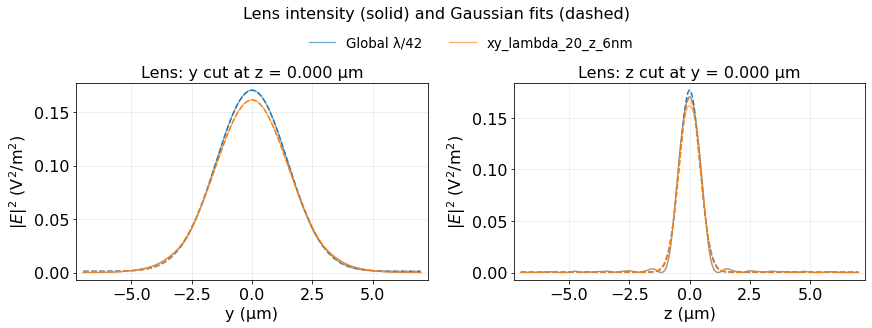

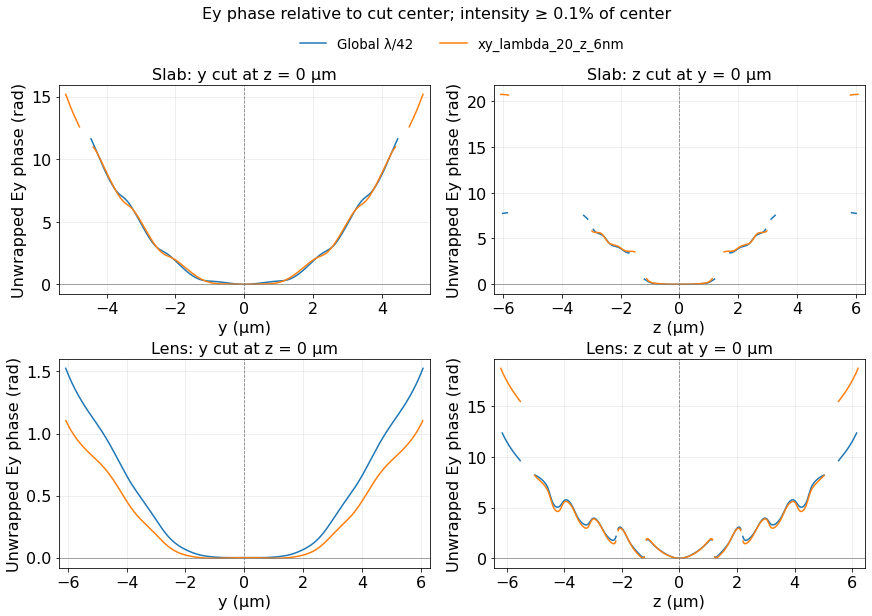

In [99]:
# Compare the new anisotropic mesh with the largest loaded global divider.
# Rerun the mesh-import cell first if additional global_lambda_N folders were added.
comparison_folder = parent_path / "xy_lambda_20_z_6nm"
finest_divider = max(mesh_data)
comparison_cases = prepare_monitor_comparison(
    mesh_data[finest_divider], comparison_folder, reference_label=f"Global λ/{finest_divider:g}",
    lens_name=lens_path, slab_name=slab_path,
)
comparison_waists = fit_lens_cases(comparison_cases, center_um=CUT_CENTER_UM)
fig_comparison_waists = plot_lens_case_fits(comparison_cases, comparison_waists,
                                          center_um=CUT_CENTER_UM)
comparison_phases, fig_comparison_phases = plot_case_phases(
    comparison_cases, component=PHASE_COMPONENT, threshold=PHASE_INTENSITY_THRESHOLD,
    center_um=CUT_CENTER_UM,
)


Lens, z divider 20: loaded xy dividers 8, 10, 14, 18, 22


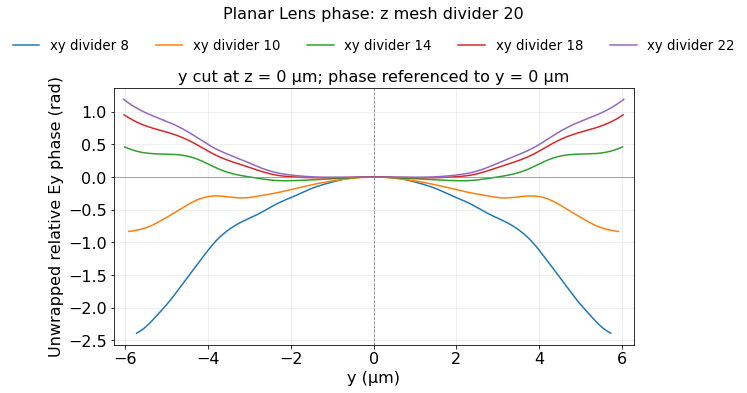

In [100]:
# Lens y-cut phase at z = 0 µm: all xy dividers in the z_20 sweep group.
lens_ycuts_z20 = load_lens_ycut_group(
    parent_path, z_divider=20, lens_name=lens_path, component=PHASE_COMPONENT,
)
lens_yphases_z20, fig_yphase_z20 = plot_xy_group_yphase(
    lens_ycuts_z20, z_divider=20, threshold=PHASE_INTENSITY_THRESHOLD,
    center_y_um=CUT_CENTER_UM[0],
)


Lens, z divider 30: loaded xy dividers 8, 10, 14, 18, 22


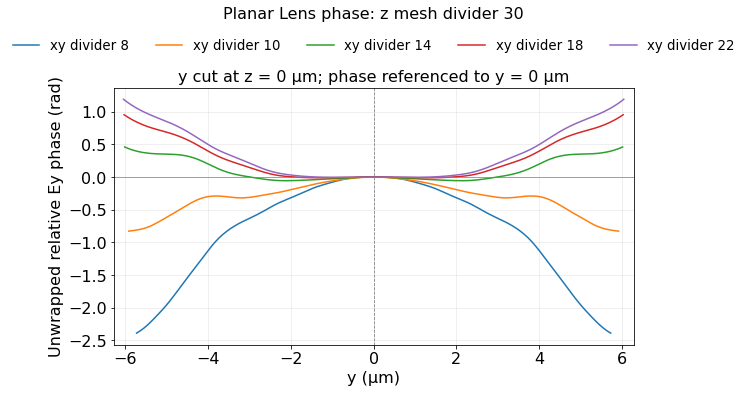

In [101]:
# Lens y-cut phase at z = 0 µm: all xy dividers in the z_30 sweep group.
lens_ycuts_z30 = load_lens_ycut_group(
    parent_path, z_divider=30, lens_name=lens_path, component=PHASE_COMPONENT,
)
lens_yphases_z30, fig_yphase_z30 = plot_xy_group_yphase(
    lens_ycuts_z30, z_divider=30, threshold=PHASE_INTENSITY_THRESHOLD,
    center_y_um=CUT_CENTER_UM[0],
)


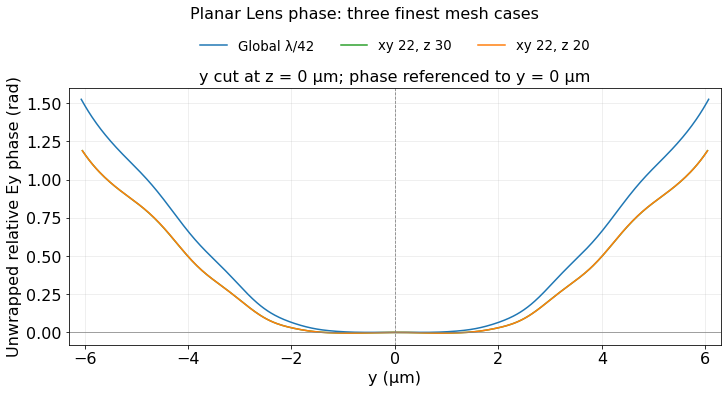

In [102]:
# Compare the three finest Lens cases along y at z = 0 µm.
# Read only these cuts; full E/H maps and earlier comparison cells are not required.
finest_phase_folders = {
    "Global λ/42": "global_lambda_42",
    "xy 22, z 30": "xy_22_z_30",
    "xy 22, z 20": "xy_22_z_20",
}
finest_lens_ycuts = {
    label: load_lens_ycut(parent_path / folder / lens_path, component=PHASE_COMPONENT)
    for label, folder in finest_phase_folders.items()
}
finest_lens_yphases, fig_finest_lens_yphase = plot_lens_yphase_comparison(
    finest_lens_ycuts, threshold=PHASE_INTENSITY_THRESHOLD,
    center_y_um=CUT_CENTER_UM[0], title="Planar Lens phase: three finest mesh cases",
)


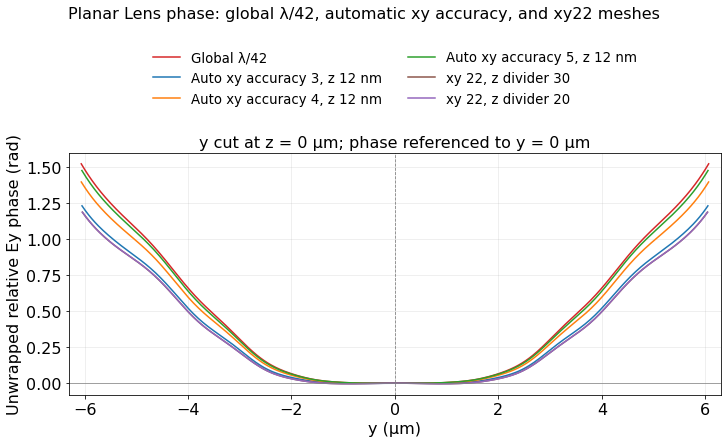

In [103]:
# Lens Ey phase along y at z = 0 µm: global, automatic xy, and xy22 mesh cases.
# Discover xy_lambda_oN_z_12nm folders; rerun to include future accuracy levels.
auto_xy_lens_ycuts = {
    "Global λ/42": load_lens_ycut(parent_path / "global_lambda_42" / lens_path,
                                  component=PHASE_COMPONENT),
    **load_auto_xy_ycut_cases(parent_path, z_step_nm=12, lens_name=lens_path,
                             component=PHASE_COMPONENT),
    "xy 22, z divider 30": load_lens_ycut(parent_path / "xy_22_z_30" / lens_path,
                                          component=PHASE_COMPONENT),
    "xy 22, z divider 20": load_lens_ycut(parent_path / "xy_22_z_20" / lens_path,
                                          component=PHASE_COMPONENT),
}
auto_xy_lens_yphases, fig_auto_xy_lens_yphase = plot_lens_yphase_comparison(
    auto_xy_lens_ycuts, threshold=PHASE_INTENSITY_THRESHOLD, legend_columns=2,
    center_y_um=CUT_CENTER_UM[0],
    title="Planar Lens phase: global λ/42, automatic xy accuracy, and xy22 meshes",
)


Signed difference: automatic xy case minus global λ/42, after referencing each phase to its center.
Intensity threshold in both cuts: 0.1% of each cut's central component intensity.
Global λ/42: recorded x = 17.993929 µm, sampled z = 0 µm
Auto xy accuracy 3: recorded x = 18.015873 µm, sampled z = 0 µm
Auto xy accuracy 4: recorded x = 17.992189 µm, sampled z = 0 µm
Auto xy accuracy 5: recorded x = 18.010101 µm, sampled z = 0 µm


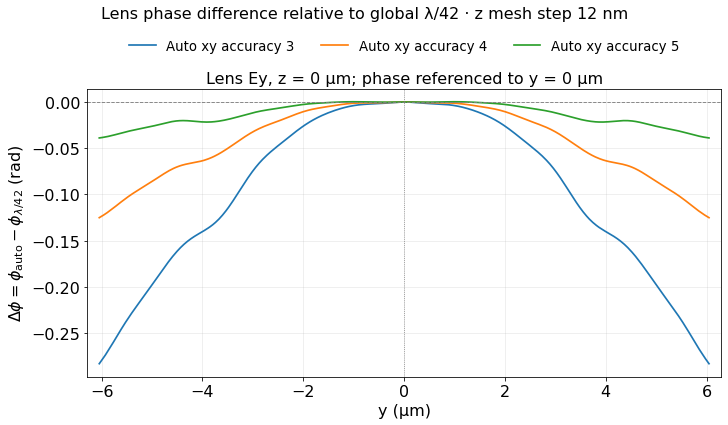

NameError: name 'mean_absolute_yphase_difference' is not defined

In [105]:
# Lens Ey phase differences at z = 0 µm: auto xy o3/o4/o5 minus global λ/42.
phase_reference_42 = load_lens_ycut(parent_path / "global_lambda_42" / lens_path, component="Ey")
phase_difference_cases = {
    f"Auto xy accuracy {accuracy}": load_lens_ycut(
        parent_path / f"xy_lambda_o{accuracy}_z_12nm" / lens_path, component="Ey",
    )
    for accuracy in (3, 4, 5)
}
lens_yphase_difference_results, fig_lens_yphase_differences = plot_lens_yphase_differences(
    phase_reference_42, phase_difference_cases,
    threshold=PHASE_INTENSITY_THRESHOLD, center_y_um=CUT_CENTER_UM[0],
)

# Spatial mean absolute difference over the common visible region of all curves.
lens_yphase_mean_abs_results = mean_absolute_yphase_difference(lens_yphase_difference_results)
